## Step 1: Organize Content by Release Year

In this step, we load the cleaned Netflix dataset and inspect the `release_year` column. This helps us prepare the data for yearly content analysis.

In [2]:
import pandas as pd 

df = pd.read_csv("../../data/processed/netflix_cleaned.csv")

df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,90,min
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",1,Season
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",125,min


### Inspect the Release Year Column

We will check the `release_year` column to understand its data type and identify any missing values before calculating yearly content counts.

In [ ]:
# Check release year data type
print("Data type:", df["release_year"].dtype)

# Count missing release years
print("Msssing release years:", df["release_year"].isna().sum())

# Display the earliest and latest release years
print("Earliest release year:", df["release_year"].min())
print("Latest release year:", df["release_year"].max())

Data type: int64
Msssing release years: 0
Earliest release year: 1925
Latest release year: 2021


## Step 2: Calculate Yearly Content Releases

In this step, we count the number of Netflix content records for each release year. This helps us understand how the volume of content varies over time.

In [ ]:
# Count content records for each release year
yearly_counts = df["release_year"].value_counts().sort_index()

# Display the yearly counts
print(yearly_counts)

release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Name: count, Length: 74, dtype: int64


## Step 3: Identify Growth and Decline Trends

Compare yearly content counts to identify years with increases or decreases in the number of content records.

In [9]:

yearly_change = yearly_counts.diff()


print(yearly_change.tail(10))

release_year
2012     51.0
2013     50.0
2014     66.0
2015    203.0
2016    346.0
2017    129.0
2018    116.0
2019   -116.0
2020    -77.0
2021   -361.0
Name: count, dtype: float64


## Step 4: Create Trend Visualizations

Create a line chart showing the number of Netflix content records by release year to visualize changes over time.

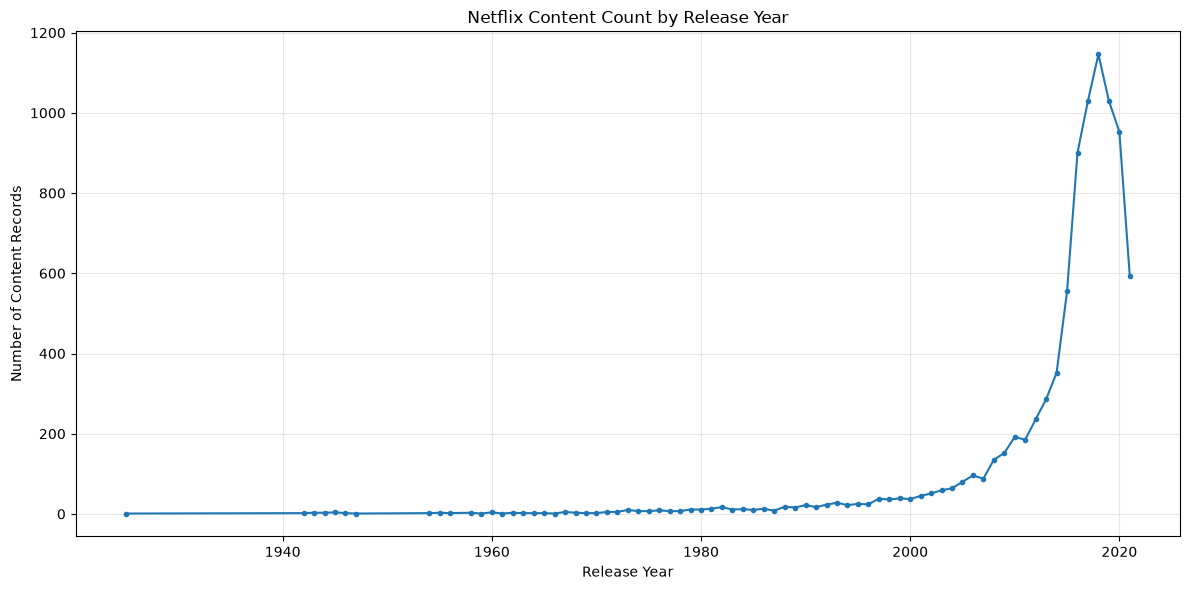

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    yearly_counts.index,
    yearly_counts.values,
    marker="o",
    markersize=3
)

plt.title("Netflix Content Count by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Content Records")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "yearly_content_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Step 5: Interpret Business Patterns

### Key Business Insights

1. **Peak year:** 2018 recorded the highest number of content records, with 1,146 titles.
2. **Growth trend:** Content counts increased substantially during the 2010s, reaching their peak in 2018.
3. **Recent decline:** Counts decreased from 1,030 in 2019 to 953 in 2020 and 592 in 2021.
4. **Historical distribution:** Earlier release years contain relatively few records compared with recent decades.

### Data Limitation

These findings describe the release years represented in the cleaned Netflix dataset. They do not directly measure Netflix's annual production or platform additions. Missing historical records and incomplete coverage of recent years may influence the observed trend.